In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d
import seaborn as sns

In [64]:
def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)

    print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")

def show_expert_contributions(contrib, contrib_norm, labels_names):
    n_exp = len(contrib)

    print("\n=== Ranked Experts ===\n")

    for i, c in sorted(enumerate(contrib), key=lambda x: -x[1]):
        name = labels_names[i]
        print(f"{i:>2} | {name:<12} | contribution: {c:>8.4f} | normalized: {contrib_norm[i]:>7.4f}")

    print("\nSummary:")
    print(f"Positive contributors: {np.sum(contrib > 0)} {np.where(contrib > 0)[0].tolist()}")
    print(f"Negative contributors: {np.sum(contrib < 0)} {np.where(contrib < 0)[0].tolist()}")

    plt.figure()
    plt.bar(range(n_exp), contrib_norm)
    plt.axhline(0, color='black')

    plt.xticks(range(n_exp), labels_names, rotation=30, ha="right")
    plt.ylabel("Normalized Contribution")

    plt.tight_layout()
    plt.show()
    
def analyze_ensemble(rootpath, expert_names=None):
    labels = np.load(os.path.join(rootpath, "labels.npy"))

    # PRINT PERFORMANCE METRICS  

    ensemble_logLR = np.load(os.path.join(rootpath, "scores.npy"))
    print(f"Loaded {len(ensemble_logLR)} samples")

    print("\n#--------- OVERALL ENSEMBLE ---------#\n")
    print_metrics(ensemble_logLR, labels)

    real = ensemble_logLR[labels == 0]
    fake = ensemble_logLR[labels == 1]

    print(f"Real mean score: {real.mean():.4f}")
    print(f"Fake mean score: {fake.mean():.4f}\n")

    print("\n#------------ PER EXPERT ------------#\n")

    all_logLR = np.load(os.path.join(rootpath, "scores_per_expert.npy"))
    n_exp = all_logLR.shape[0]

    real_all_logLR = []
    fake_all_logLR = []

    for i in range(n_exp):
        name = expert_names[i] if expert_names else f"Expert {i}"

        print(f"--- {name} ---")
        per_expert_logLR = all_logLR[i]

        print_metrics(per_expert_logLR, labels)

        real_i = per_expert_logLR[labels == 0]
        fake_i = per_expert_logLR[labels == 1]

        print(f"Real mean score: {real_i.mean():.4f}")
        print(f"Fake mean score: {fake_i.mean():.4f}\n")

        real_all_logLR.append(real_i)
        fake_all_logLR.append(fake_i)

    # HIGHLIGHT EXPERT CONTRIBUTIONS    

    n_exp = all_logLR.shape[0]   # no. of experts
    N = all_logLR.shape[1]       # no. of test samples
    
    contrib = np.zeros(n_exp)
    
    for i in range(N):
        y_sign = 1 if labels[i] == 1 else -1
    
        for e in range(n_exp):
            contrib[e] += all_logLR[e, i] * y_sign
    
    contrib /= N
    contrib_norm = contrib / np.max(np.abs(contrib))
    
    show_expert_contributions(contrib, contrib_norm, names)
    
    return {
        "ensemble": ensemble_logLR,
        "per_expert": all_logLR,
        "labels": labels,
        "real": real_all_logLR,
        "fake": fake_all_logLR
    }

def plot_platt(a, b, logits, ax=None, title=""):
    if ax is None:
        ax = plt.gca()
    z_full = np.linspace(-10, 10, 1000)
    p_full = 1 / (1 + np.exp(-(a * z_full + b)))
    
    z_min, z_max = logits.min(), logits.max()
    z_data = np.linspace(z_min, z_max, 500)
    
    p_data = 1 / (1 + np.exp(-(a * z_data + b)))
    p_min = 1 / (1 + np.exp(-(a * z_min + b)))
    p_max = 1 / (1 + np.exp(-(a * z_max + b)))
    
    ax.plot(z_full, p_full, label="Full sigmoid", alpha=0.5)
    ax.plot(z_data, p_data, linewidth=3, label="Used region")
    
    ax.scatter([z_min, z_max], [p_min, p_max], color="red", zorder=3, label="min/max raw logits")
    ax.axvline(z_min, linestyle="--", alpha=0.5)
    ax.axvline(z_max, linestyle="--", alpha=0.5)

    lbound = np.percentile(logits, 5)
    hbound = np.percentile(logits, 95)
    ax.axvspan(lbound, hbound, color="yellow", alpha=0.3)
    ax.axvline(lbound, color="grey")
    ax.axvline(hbound, color="grey")
    
    ax.set_xlabel("logits (z)")
    ax.set_ylabel("probability")
    ax.set_title(title)
    #ax.legend()
    ax.grid()

def plot_platt_all_attacks(root_base, attacks, expert_names):
    n_exp = len(expert_names)
    n_att = len(attacks)

    fig, axes = plt.subplots(n_exp, n_att, figsize=(4*n_att, 3*n_exp), squeeze=False)

    for j, att in enumerate(attacks):
        path = os.path.join(root_base, att)

        logits_all = np.load(os.path.join(path, 'raw_logits_per_expert.npy'))
        a_all = np.load(os.path.join(root_base, 'all_a.npy'))
        b_all = np.load(os.path.join(root_base, 'all_b.npy'))

        for i in range(n_exp):
            ax = axes[i, j]

            logits = logits_all[i]
            a = a_all[i]
            b = b_all[i]

            plot_platt(a, b, logits, ax=ax)

            # --- labels ---
            if i == 0:
                ax.set_title(att)  # colonna = attacco
            if j == 0:
                ax.set_ylabel(expert_names[i])  # riga = expert

    plt.tight_layout()
    plt.show()

In [3]:
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy']

# Test set: ASVspoof 2019
### Calibration set from 19 

In [11]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']

## Experts trained on 19

Loaded 19171 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 84.53%, EER: 24.07%
Real mean score: -1.4804
Fake mean score: 1.8393


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 42.34%, EER: 55.89%
Real mean score: 0.0011
Fake mean score: 0.0002

--- F0 Incons ---
AUC: 67.85%, EER: 37.24%
Real mean score: -0.0751
Fake mean score: -0.0160

--- Oversmooth ---
AUC: 52.67%, EER: 50.03%
Real mean score: -0.1105
Fake mean score: 0.0612

--- Phase ---
AUC: 70.96%, EER: 35.84%
Real mean score: -0.1678
Fake mean score: 0.5729

--- Energy ---
AUC: 82.19%, EER: 25.04%
Real mean score: -1.1281
Fake mean score: 1.2211


=== Ranked Experts ===

 4 | Energy       | contribution:   1.1754 | normalized:  1.0000
 3 | Phase        | contribution:   0.3737 | normalized:  0.3180
 2 | Oversmooth   | contribution:   0.0854 | normalized:  0.0727
 1 | F0 Incons    | contribution:   0.0288 | normalized:  0.0245
 0 | Flat Pitch   | contribution:  -0.0004 | normalized: -0.0004

Summary:
Po

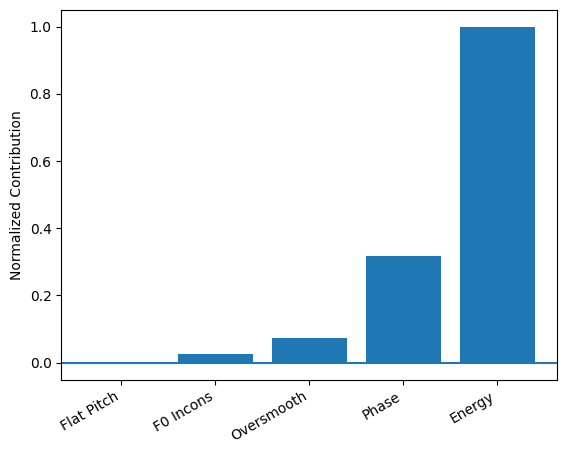

In [14]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/scale_on_calibration/ALL"
res = analyze_ensemble(rootpath, expert_names=names)

### Analyze A04

In [27]:
A04_path ="/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/scale_on_calibration/A04"

A04_labels = np.load(os.path.join(A04_path, 'labels.npy'))
A04_ensemble_logLR = np.load(os.path.join(A04_path, 'scores.npy'))
                             
A04_logLR_per_expert = np.load(os.path.join(A04_path, 'scores_per_expert.npy'))
A04_probs_per_expert = np.load(os.path.join(A04_path, 'scaled_logits_per_expert.npy'))
A04_logits_per_expert = np.load(os.path.join(A04_path, 'raw_logits_per_expert.npy'))

A04_a_coeff = np.load(os.path.join(A04_path, 'all_a.npy'))
A04_b_coeff = np.load(os.path.join(A04_path, 'all_b.npy'))

In [26]:
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy']
labels = A04_labels

for i in range(A04_logLR_per_expert.shape[0]):
    name = names[i]

    for tag, data in zip(
        ["logits", "probs", "logLR"],
        [A04_logits_per_expert, A04_probs_per_expert, A04_logLR_per_expert]
    ):
        scores = data[i]

        real = scores[labels == 0]
        fake = scores[labels == 1]

        real_m = real.mean()
        fake_m = fake.mean()

        check = "GOOD" if fake_m > real_m else "BAD"

        print(f"{name:>12} | {tag:>6} | real μ: {real_m:>8.4f} | fake μ: {fake_m:>8.4f} | {check}")

    print("-" * 80)


  Flat Pitch | logits | real μ:  -2.6254 | fake μ:  -1.9985 | GOOD
  Flat Pitch |  probs | real μ:   0.5048 | fake μ:   0.5098 | GOOD
  Flat Pitch |  logLR | real μ:   0.0013 | fake μ:   0.0021 | GOOD
--------------------------------------------------------------------------------
   F0 Incons | logits | real μ:  -1.9642 | fake μ:  -0.1178 | GOOD
   F0 Incons |  probs | real μ:   0.4966 | fake μ:   0.4496 | BAD
   F0 Incons |  logLR | real μ:  -0.0741 | fake μ:  -0.1031 | BAD
--------------------------------------------------------------------------------
  Oversmooth | logits | real μ:  -2.0846 | fake μ:  -2.1682 | BAD
  Oversmooth |  probs | real μ:   0.4617 | fake μ:   0.4549 | BAD
  Oversmooth |  logLR | real μ:  -0.1358 | fake μ:  -0.1465 | BAD
--------------------------------------------------------------------------------
       Phase | logits | real μ:  -2.8861 | fake μ:  -2.9745 | BAD
       Phase |  probs | real μ:   0.4861 | fake μ:   0.4610 | BAD
       Phase |  logLR | rea

-0.10268665448781371 -0.21549909240758733
0.682826491453293 1.1410042754333738


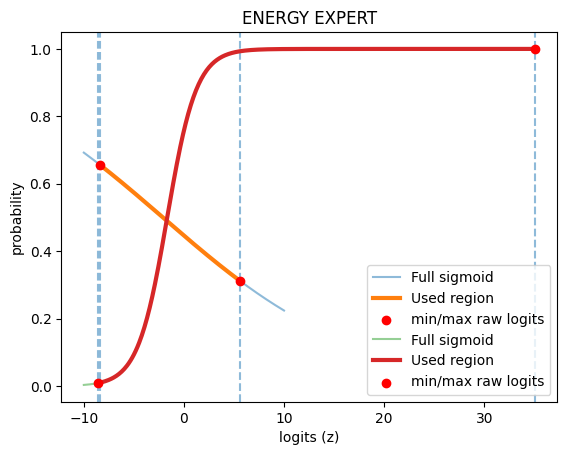

In [48]:
print(A04_a_coeff[1], A04_b_coeff[1])  # for expert 1
print(A04_a_coeff[4], A04_b_coeff[4])  # for expert 4

plot_platt(A04_a_coeff[1], A04_b_coeff[1], A04_logits_per_expert[1], title='F0 INCONS. EXPERT')  # orange
plot_platt(A04_a_coeff[4], A04_b_coeff[4], A04_logits_per_expert[4], title='ENERGY EXPERT')      # red

### Check all sigmoids

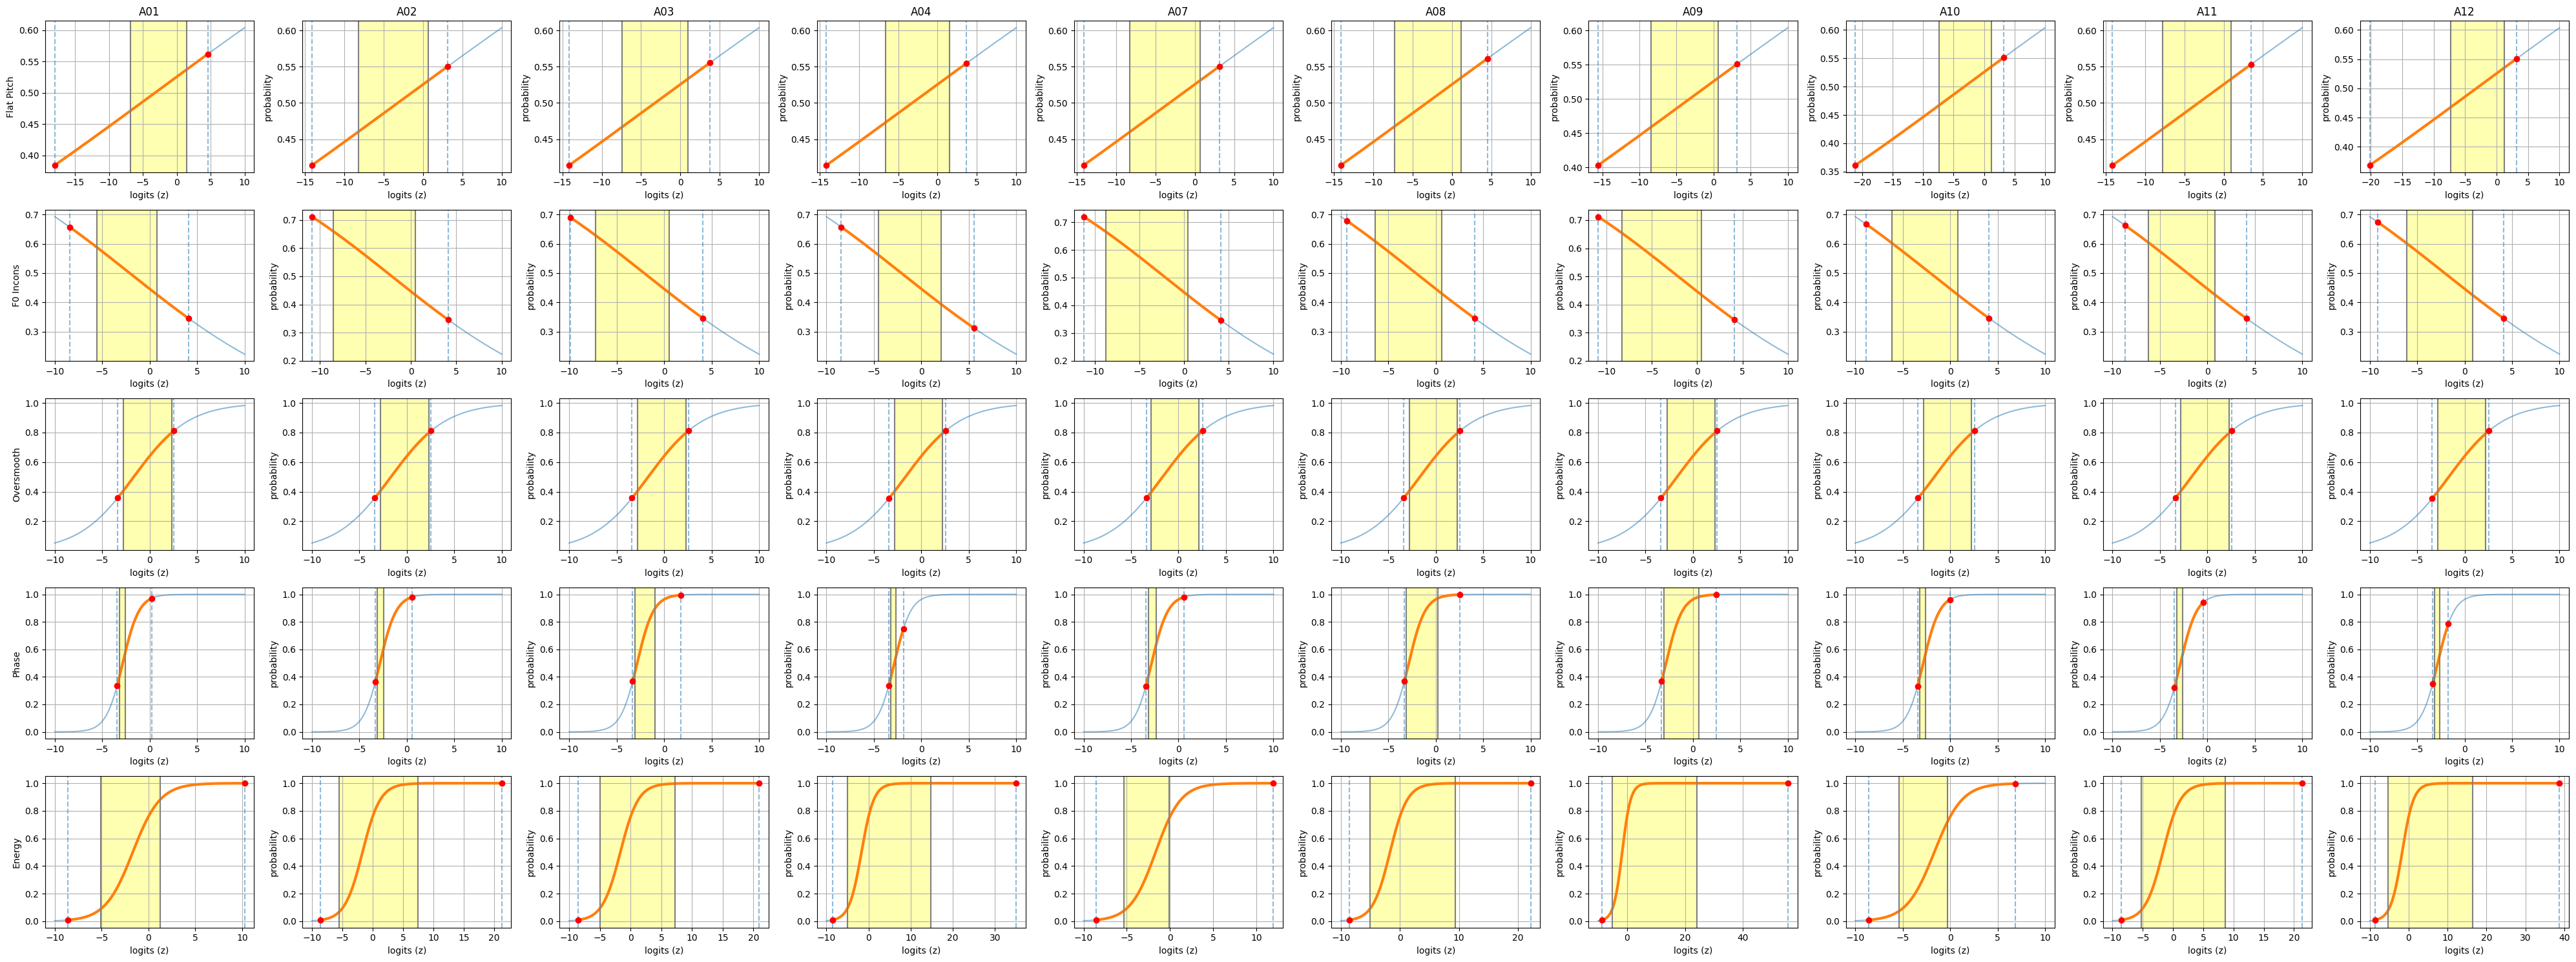

In [59]:
root_base = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/scale_on_calibration"
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy']
plot_platt_all_attacks(root_base, generator_list, names)


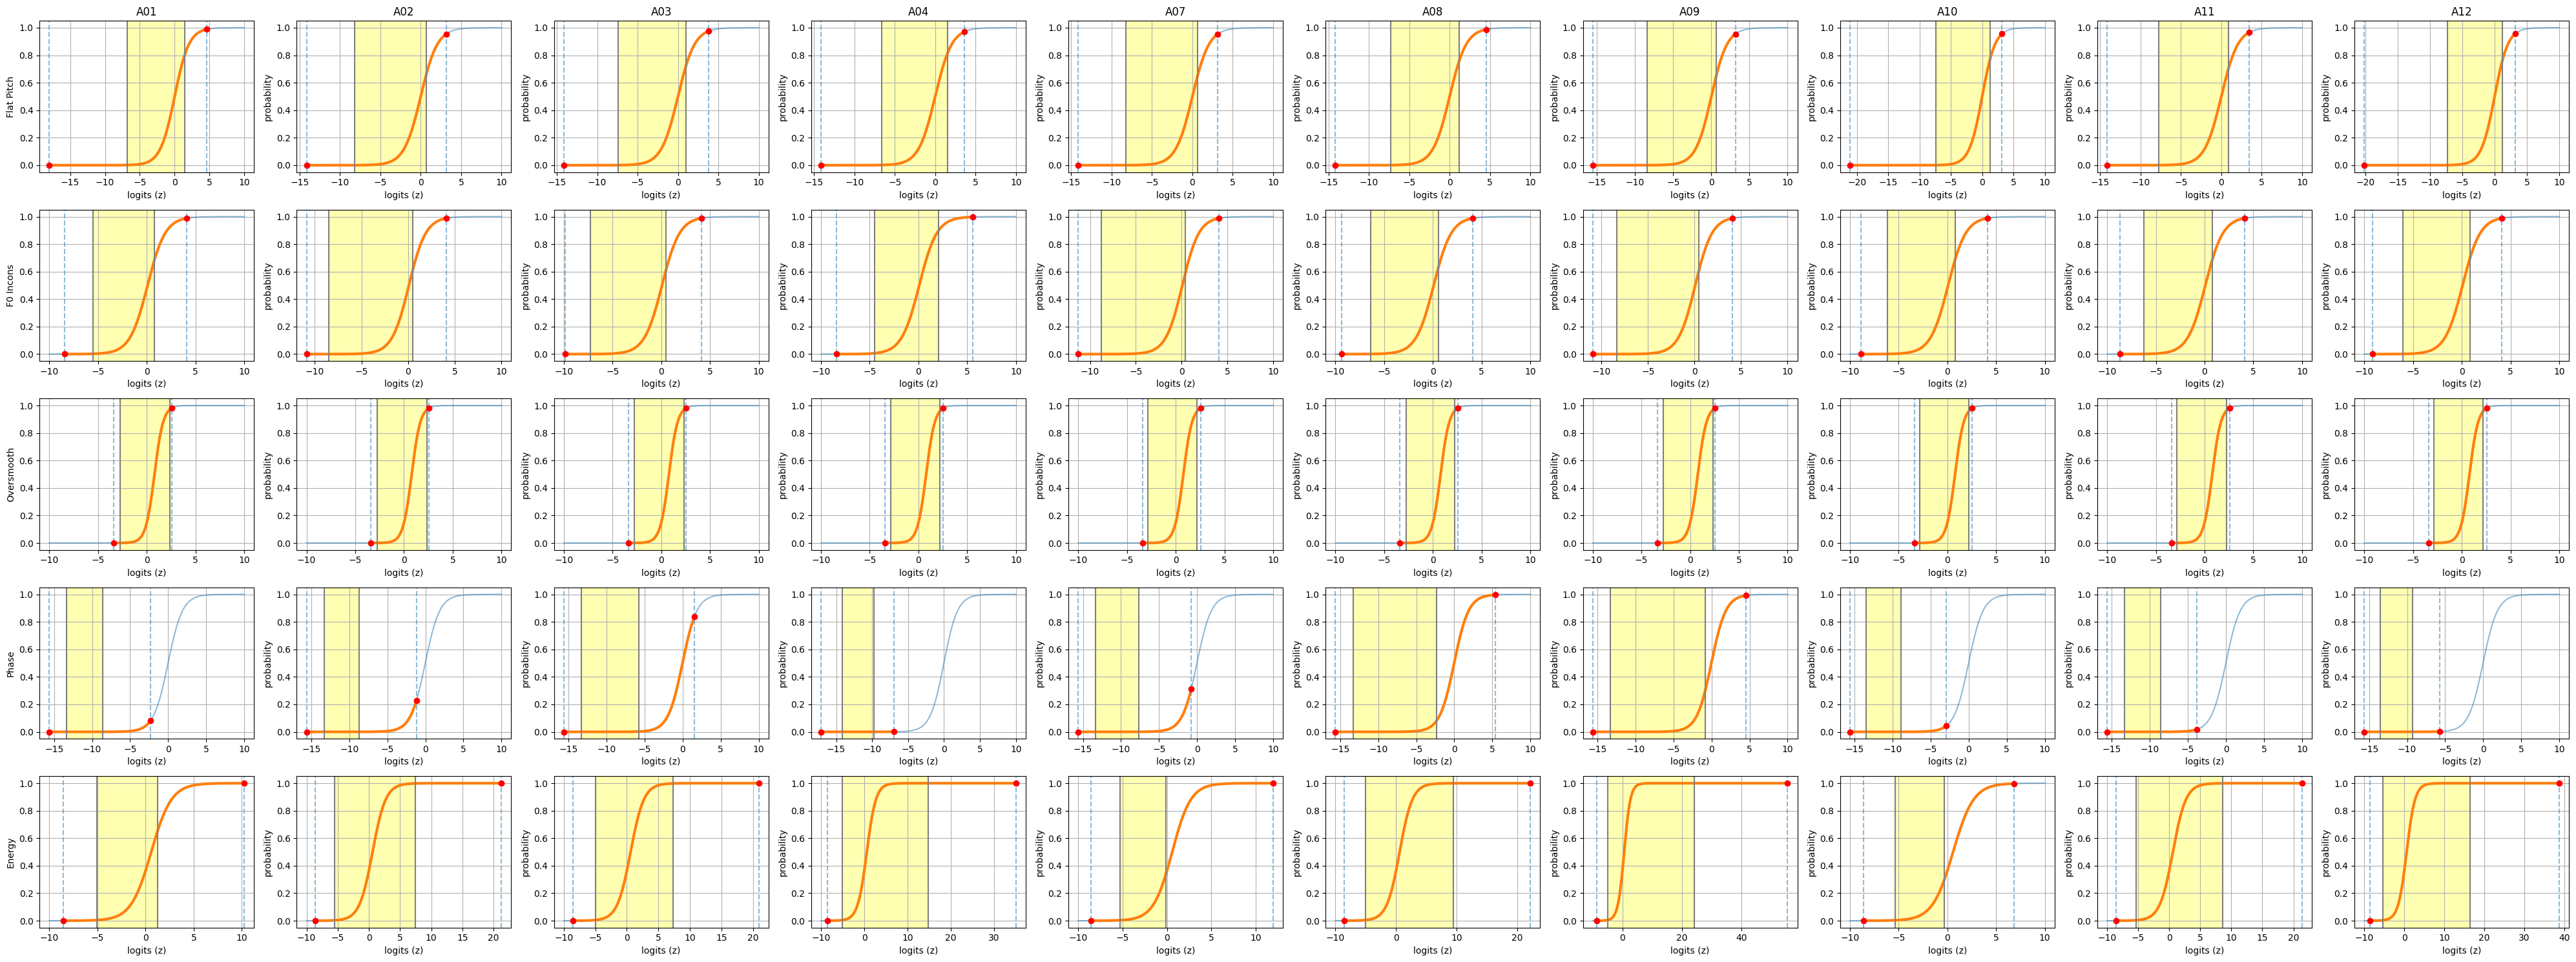

In [60]:
root_base = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/scale_on_validation"
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy']
plot_platt_all_attacks(root_base, generator_list, names)


# Scale each expert on its target, calibrate on pooled targets

## Overall

Loaded 19171 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 88.98%, EER: 19.91%
Real mean score: -1.5318
Fake mean score: 2.1602


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 42.33%, EER: 55.88%
Real mean score: 0.0077
Fake mean score: -0.0005

--- F0 Incons ---
AUC: 66.34%, EER: 38.73%
Real mean score: -0.1121
Fake mean score: 0.1230

--- Oversmooth ---
AUC: 52.73%, EER: 49.98%
Real mean score: -0.1056
Fake mean score: 0.0674

--- Phase ---
AUC: 77.26%, EER: 30.35%
Real mean score: -0.2603
Fake mean score: 0.5927

--- Energy ---
AUC: 82.19%, EER: 25.04%
Real mean score: -1.0615
Fake mean score: 1.3777


=== Ranked Experts ===

 4 | Energy       | contribution:   1.2222 | normalized:  1.0000
 3 | Phase        | contribution:   0.4293 | normalized:  0.3512
 1 | F0 Incons    | contribution:   0.1176 | normalized:  0.0962
 2 | Oversmooth   | contribution:   0.0862 | normalized:  0.0705
 0 | Flat Pitch   | contribution:  -0.0041 | normalized: -0.0033

Summary:
Po

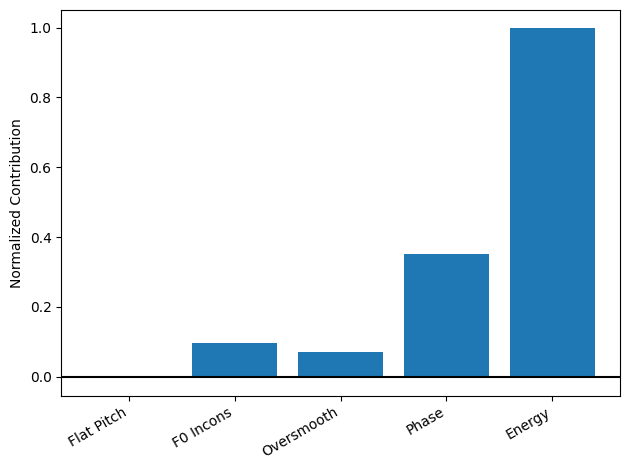

In [61]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/scale_on_calibration_v2/ALL"
res = analyze_ensemble(rootpath, expert_names=names)

## Per attack


########################################################################################################################
#--------------------------------------------------------- A01 ---------------------------------------------------------#
########################################################################################################################

Loaded 1898 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 89.43%, EER: 17.97%
Real mean score: -1.5391
Fake mean score: 0.8012


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 57.62%, EER: 44.21%
Real mean score: 0.0091
Fake mean score: 0.0175

--- F0 Incons ---
AUC: 55.39%, EER: 46.33%
Real mean score: -0.1030
Fake mean score: -0.0419

--- Oversmooth ---
AUC: 79.52%, EER: 30.20%
Real mean score: -0.1313
Fake mean score: 0.6362

--- Phase ---
AUC: 73.15%, EER: 33.44%
Real mean score: -0.2409
Fake mean score: 0.2364

--- Energy ---
AUC: 79.96%, EER: 25.29%
Real mean score: -1.0731
Fake mean score: -0.04

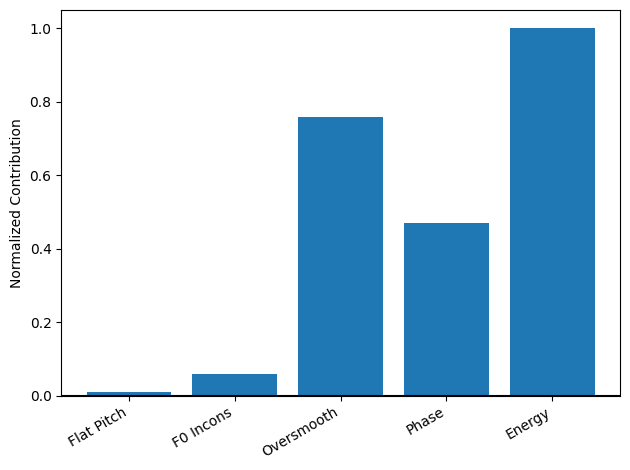


########################################################################################################################
#--------------------------------------------------------- A02 ---------------------------------------------------------#
########################################################################################################################

Loaded 1926 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 85.23%, EER: 27.01%
Real mean score: -1.5391
Fake mean score: 1.5526


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 30.83%, EER: 63.45%
Real mean score: 0.0091
Fake mean score: -0.0143

--- F0 Incons ---
AUC: 78.20%, EER: 29.44%
Real mean score: -0.1030
Fake mean score: 0.3319

--- Oversmooth ---
AUC: 65.98%, EER: 39.59%
Real mean score: -0.1313
Fake mean score: 0.2277

--- Phase ---
AUC: 72.40%, EER: 34.75%
Real mean score: -0.2409
Fake mean score: 0.2080

--- Energy ---
AUC: 71.92%, EER: 32.28%
Real mean score: -1.0731
Fake mean score: 0.799

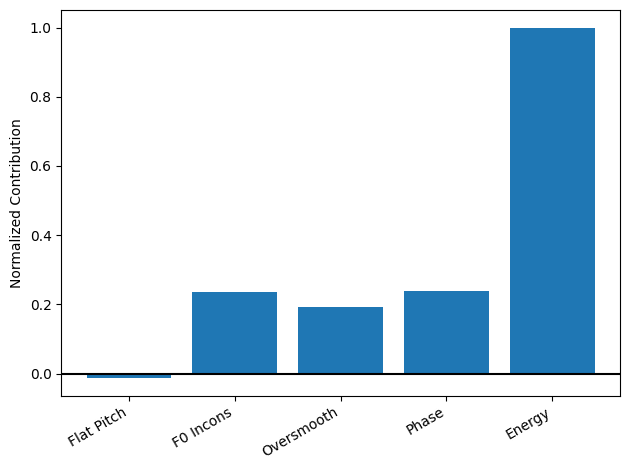


########################################################################################################################
#--------------------------------------------------------- A03 ---------------------------------------------------------#
########################################################################################################################

Loaded 1931 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 98.88%, EER: 5.10%
Real mean score: -1.5391
Fake mean score: 3.6209


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 39.10%, EER: 58.45%
Real mean score: 0.0091
Fake mean score: -0.0012

--- F0 Incons ---
AUC: 71.09%, EER: 34.55%
Real mean score: -0.1030
Fake mean score: 0.2076

--- Oversmooth ---
AUC: 63.55%, EER: 40.61%
Real mean score: -0.1313
Fake mean score: 0.1114

--- Phase ---
AUC: 88.08%, EER: 20.00%
Real mean score: -0.2409
Fake mean score: 0.9956

--- Energy ---
AUC: 96.54%, EER: 9.14%
Real mean score: -1.0731
Fake mean score: 2.3076


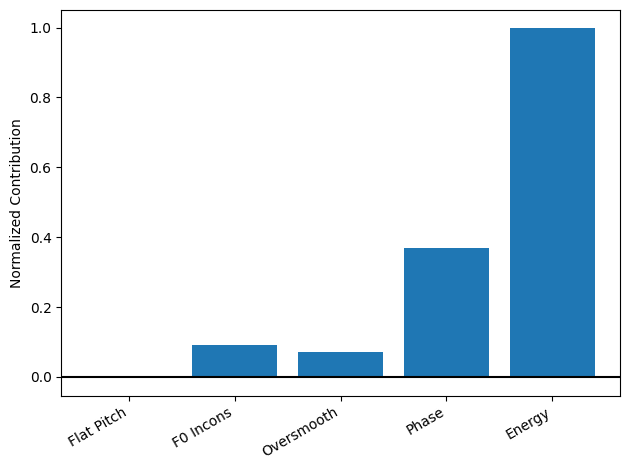


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################

Loaded 1880 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 87.92%, EER: 22.15%
Real mean score: -1.5391
Fake mean score: 1.9032


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 56.84%, EER: 45.48%
Real mean score: 0.0091
Fake mean score: 0.0175

--- F0 Incons ---
AUC: 57.19%, EER: 43.02%
Real mean score: -0.1030
Fake mean score: -0.0421

--- Oversmooth ---
AUC: 41.65%, EER: 57.60%
Real mean score: -0.1313
Fake mean score: -0.1428

--- Phase ---
AUC: 41.82%, EER: 56.11%
Real mean score: -0.2409
Fake mean score: -0.3244

--- Energy ---
AUC: 89.75%, EER: 19.06%
Real mean score: -1.0731
Fake mean score: 2.3

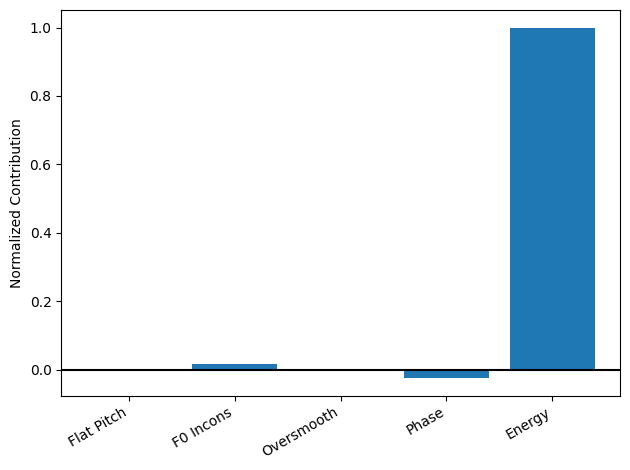


########################################################################################################################
#--------------------------------------------------------- A07 ---------------------------------------------------------#
########################################################################################################################

Loaded 1940 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 85.31%, EER: 23.80%
Real mean score: -1.5391
Fake mean score: 0.1056


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 28.99%, EER: 64.61%
Real mean score: 0.0091
Fake mean score: -0.0159

--- F0 Incons ---
AUC: 81.41%, EER: 26.57%
Real mean score: -0.1030
Fake mean score: 0.3811

--- Oversmooth ---
AUC: 38.90%, EER: 58.76%
Real mean score: -0.1313
Fake mean score: -0.1586

--- Phase ---
AUC: 83.97%, EER: 24.02%
Real mean score: -0.2409
Fake mean score: 0.6486

--- Energy ---
AUC: 63.86%, EER: 38.74%
Real mean score: -1.0731
Fake mean score: -0.7

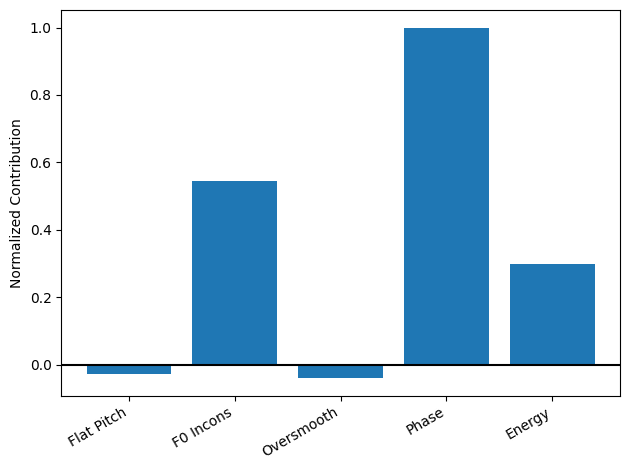


########################################################################################################################
#--------------------------------------------------------- A08 ---------------------------------------------------------#
########################################################################################################################

Loaded 1933 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 99.51%, EER: 3.53%
Real mean score: -1.5391
Fake mean score: 4.3562


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 47.09%, EER: 51.51%
Real mean score: 0.0091
Fake mean score: 0.0062

--- F0 Incons ---
AUC: 64.01%, EER: 39.62%
Real mean score: -0.1030
Fake mean score: 0.0765

--- Oversmooth ---
AUC: 54.58%, EER: 48.78%
Real mean score: -0.1313
Fake mean score: -0.0455

--- Phase ---
AUC: 97.17%, EER: 8.82%
Real mean score: -0.2409
Fake mean score: 1.6956

--- Energy ---
AUC: 96.96%, EER: 8.37%
Real mean score: -1.0731
Fake mean score: 2.6233



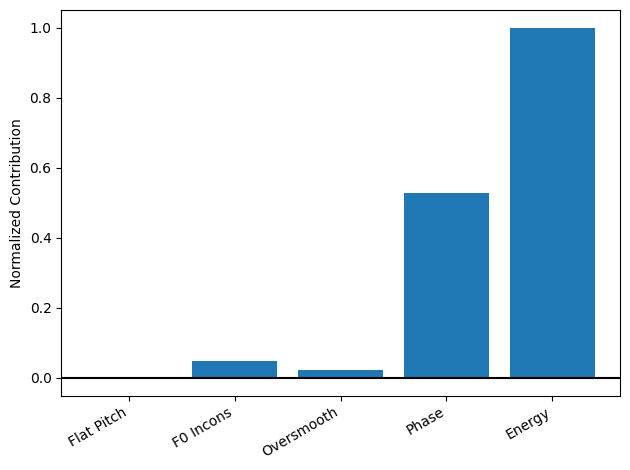


########################################################################################################################
#--------------------------------------------------------- A09 ---------------------------------------------------------#
########################################################################################################################

Loaded 1939 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 99.67%, EER: 2.87%
Real mean score: -1.5391
Fake mean score: 5.7900


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 26.06%, EER: 67.94%
Real mean score: 0.0091
Fake mean score: -0.0204

--- F0 Incons ---
AUC: 80.90%, EER: 28.16%
Real mean score: -0.1030
Fake mean score: 0.3588

--- Oversmooth ---
AUC: 74.59%, EER: 33.87%
Real mean score: -0.1313
Fake mean score: 0.4580

--- Phase ---
AUC: 98.97%, EER: 4.71%
Real mean score: -0.2409
Fake mean score: 1.9231

--- Energy ---
AUC: 97.23%, EER: 8.62%
Real mean score: -1.0731
Fake mean score: 3.0704



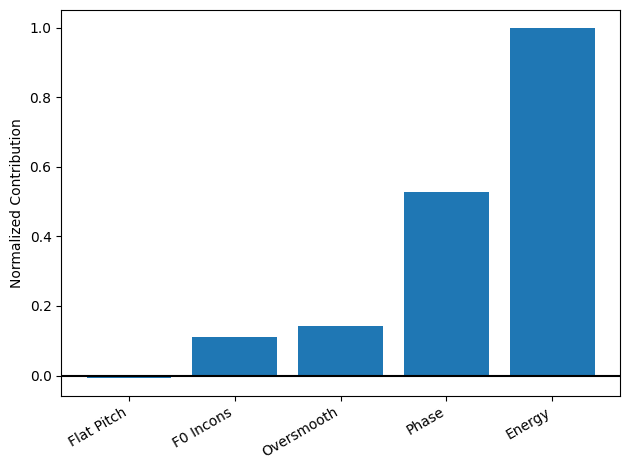


########################################################################################################################
#--------------------------------------------------------- A10 ---------------------------------------------------------#
########################################################################################################################

Loaded 1898 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 65.35%, EER: 38.98%
Real mean score: -1.5391
Fake mean score: -0.9393


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 43.06%, EER: 55.47%
Real mean score: 0.0091
Fake mean score: 0.0018

--- F0 Incons ---
AUC: 57.26%, EER: 45.38%
Real mean score: -0.1030
Fake mean score: -0.0094

--- Oversmooth ---
AUC: 41.40%, EER: 57.68%
Real mean score: -0.1313
Fake mean score: -0.1228

--- Phase ---
AUC: 68.30%, EER: 36.05%
Real mean score: -0.2409
Fake mean score: 0.1035

--- Energy ---
AUC: 58.14%, EER: 43.89%
Real mean score: -1.0731
Fake mean score: -0.

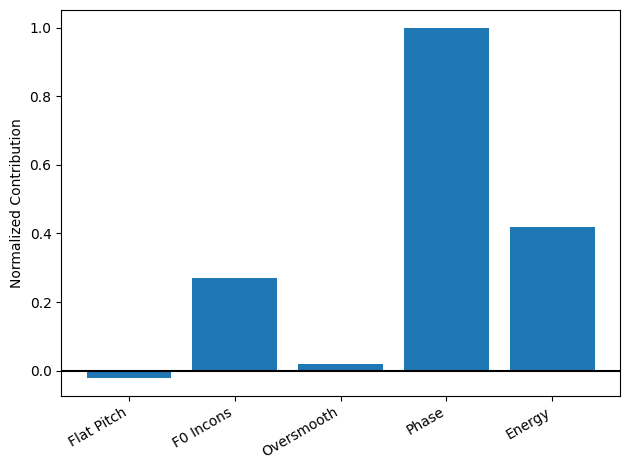


########################################################################################################################
#--------------------------------------------------------- A11 ---------------------------------------------------------#
########################################################################################################################

Loaded 1902 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 89.51%, EER: 19.46%
Real mean score: -1.5391
Fake mean score: 1.9562


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 41.55%, EER: 56.11%
Real mean score: 0.0091
Fake mean score: -0.0001

--- F0 Incons ---
AUC: 58.54%, EER: 44.42%
Real mean score: -0.1030
Fake mean score: 0.0147

--- Oversmooth ---
AUC: 45.18%, EER: 56.11%
Real mean score: -0.1313
Fake mean score: -0.0420

--- Phase ---
AUC: 78.28%, EER: 29.33%
Real mean score: -0.2409
Fake mean score: 0.3321

--- Energy ---
AUC: 82.28%, EER: 25.19%
Real mean score: -1.0731
Fake mean score: 1.65

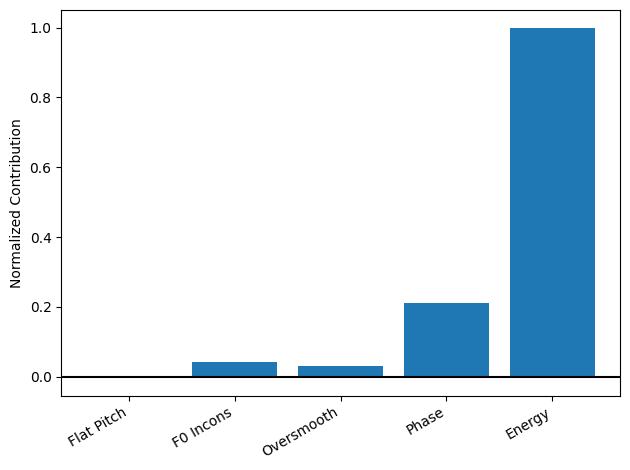


########################################################################################################################
#--------------------------------------------------------- A12 ---------------------------------------------------------#
########################################################################################################################

Loaded 1876 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 89.27%, EER: 18.18%
Real mean score: -1.5391
Fake mean score: 2.2697


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 45.30%, EER: 54.55%
Real mean score: 0.0091
Fake mean score: 0.0050

--- F0 Incons ---
AUC: 55.04%, EER: 47.17%
Real mean score: -0.1030
Fake mean score: -0.0297

--- Oversmooth ---
AUC: 39.32%, EER: 58.45%
Real mean score: -0.1313
Fake mean score: -0.1646

--- Phase ---
AUC: 59.28%, EER: 43.78%
Real mean score: -0.2409
Fake mean score: -0.0833

--- Energy ---
AUC: 86.44%, EER: 18.93%
Real mean score: -1.0731
Fake mean score: 2.5

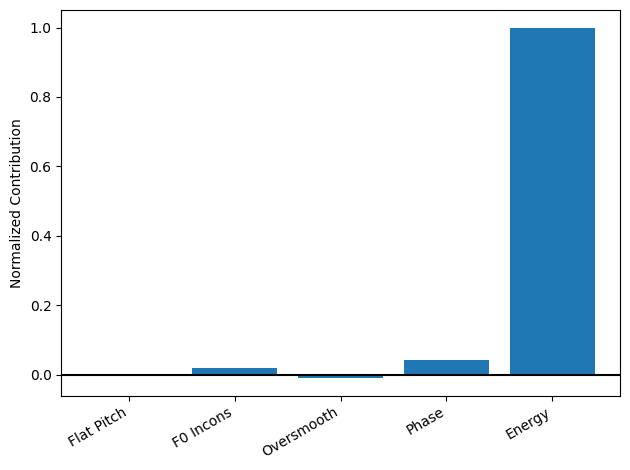

In [67]:
for a in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {a} {'-'*57}#")
    print(f"{'#'*120}\n")
    
    path = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/scale_on_calibration_v2/{a}"
    res = analyze_ensemble(path, expert_names=names)

## Analyze sigmoids

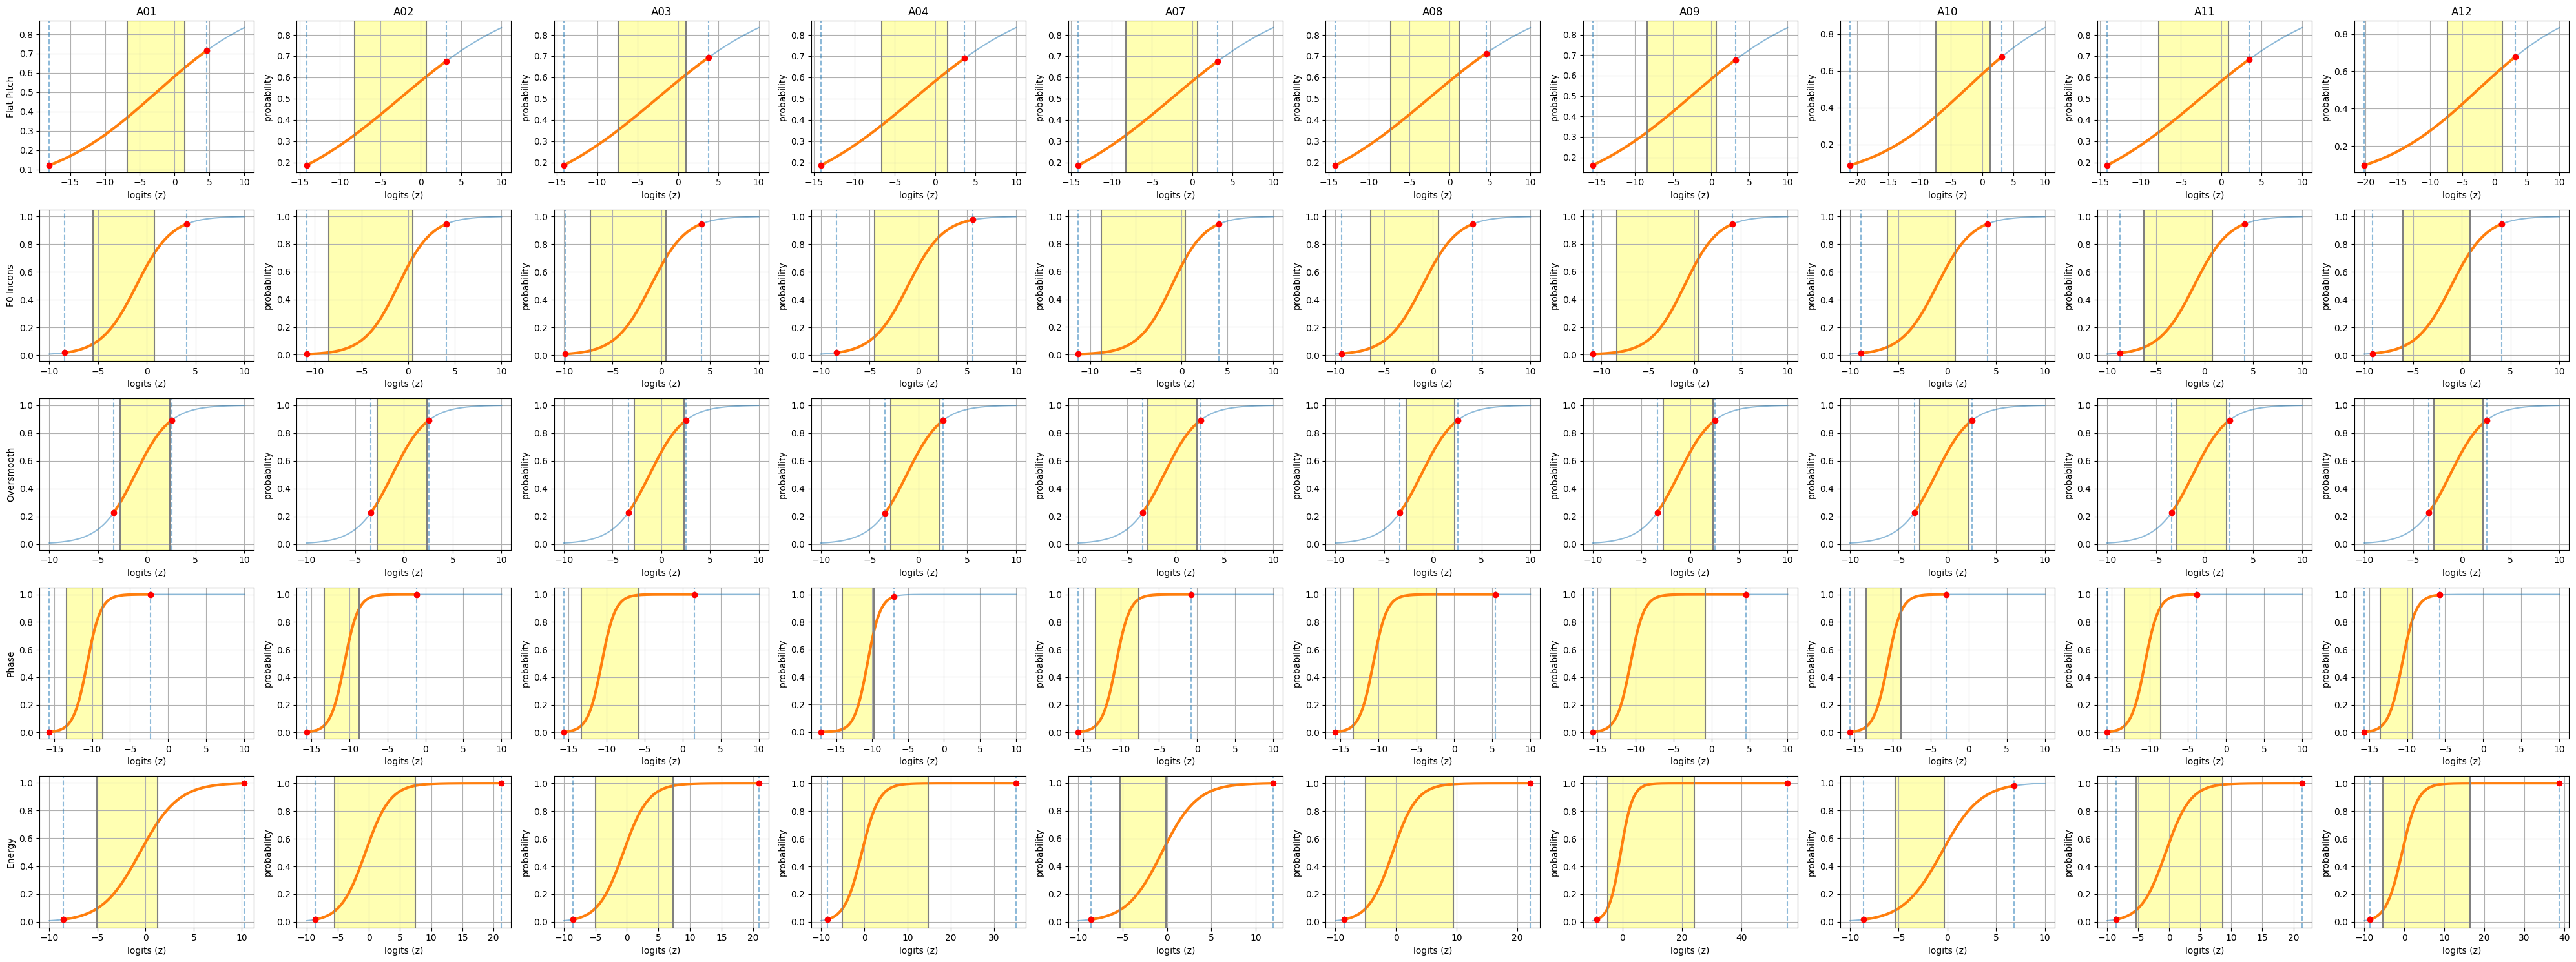

In [66]:
root_base = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/scale_on_calibration_v2"
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy']
plot_platt_all_attacks(root_base, generator_list, names)


## Experts trained on 5

Loaded 19171 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 74.70%, EER: 32.58%
Real mean score: -0.5562
Fake mean score: 0.5497


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 46.03%, EER: 53.39%
Real mean score: -0.0017
Fake mean score: -0.0175

--- F0 Incons ---
AUC: 53.34%, EER: 46.03%
Real mean score: -0.0669
Fake mean score: -0.0660

--- Oversmooth ---
AUC: 57.43%, EER: 44.82%
Real mean score: -0.0685
Fake mean score: 0.0504

--- Phase ---
AUC: 67.42%, EER: 37.48%
Real mean score: -0.1066
Fake mean score: 0.2085

--- Energy ---
AUC: 67.74%, EER: 38.37%
Real mean score: -0.3124
Fake mean score: 0.3745


=== Ranked Experts ===

 4 | Energy       | contribution:   0.3440 | normalized:  1.0000
 3 | Phase        | contribution:   0.1584 | normalized:  0.4605
 2 | Oversmooth   | contribution:   0.0593 | normalized:  0.1724
 1 | F0 Incons    | contribution:  -0.0007 | normalized: -0.0020
 0 | Flat Pitch   | contribution:  -0.0081 | normalized: -0.0235

Summary:


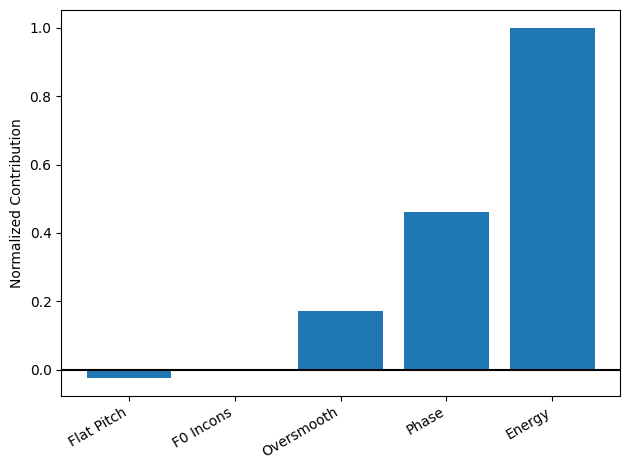

In [68]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv5/scale_on_calibration_v2/ALL"
res = analyze_ensemble(rootpath, expert_names=names)

# Test set: ASVspoof 5
### Calibration set from 5


In [ ]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A14']

## Experts trained on 5

Loaded 25006 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 65.33%, EER: 38.61%
Real mean score: -0.0479
Fake mean score: 0.3780


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 56.54%, EER: 45.46%
Real mean score: -0.0129
Fake mean score: 0.0639

--- F0 Incons ---
AUC: 64.23%, EER: 39.23%
Real mean score: -0.0762
Fake mean score: 0.2468

--- Oversmooth ---
AUC: 50.91%, EER: 50.07%
Real mean score: 0.0268
Fake mean score: 0.0317

--- Phase ---
AUC: 52.30%, EER: 49.09%
Real mean score: -0.0115
Fake mean score: -0.0109

--- Energy ---
AUC: 55.12%, EER: 45.24%
Real mean score: 0.0259
Fake mean score: 0.0464


=== Ranked Experts ===

 1 | F0 Incons    | contribution:   0.1584 | normalized:  1.0000
 0 | Flat Pitch   | contribution:   0.0375 | normalized:  0.2366
 4 | Energy       | contribution:   0.0090 | normalized:  0.0566
 2 | Oversmooth   | contribution:   0.0014 | normalized:  0.0090
 3 | Phase        | contribution:   0.0007 | normalized:  0.0044

Summary:
Pos

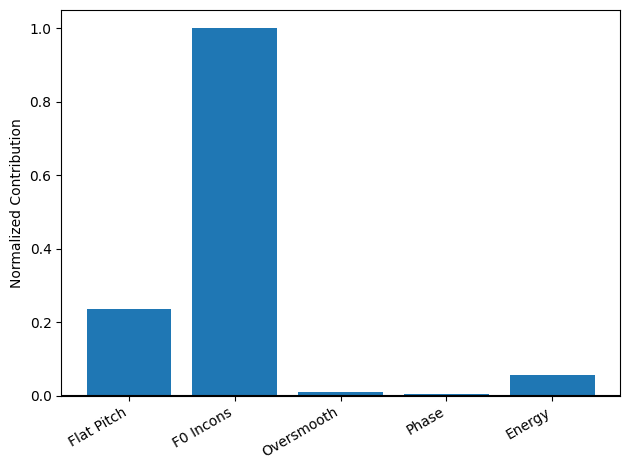

In [69]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_asv5/scale_on_calibration_v2/ALL"
res = analyze_ensemble(rootpath, expert_names=names)

## Experts trained on 19